In [5]:
# 1. Import Required Libraries
import os
import json
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from static_feature_extraction import StaticFeatureExtractor, compute_completion_percentage

Attempting to load: reference_images/task1_reference-copy/reference_two-pentagon.png
Loaded image: reference_images/task1_reference-copy/reference_two-pentagon.png shape=(649, 1024)
Attempting to load: reference_images/task2_reference-copy/reference_houseDrawing.png
Loaded image: reference_images/task2_reference-copy/reference_houseDrawing.png shape=(350, 426)
Attempting to load: reference_images/task3_freehand/reference_clock drawing.jpg
Loaded image: reference_images/task3_freehand/reference_clock drawing.jpg shape=(820, 820)
Attempting to load: user_sessions/task-1-two-pentagon-copy.png
Loaded image: user_sessions/task-1-two-pentagon-copy.png shape=(650, 900)
Attempting to load: user_sessions/task-2-house-drawing-copy.png
Loaded image: user_sessions/task-2-house-drawing-copy.png shape=(650, 900)
Attempting to load: user_sessions/task-3-clock-drawing.png
Loaded image: user_sessions/task-3-clock-drawing.png shape=(650, 900)


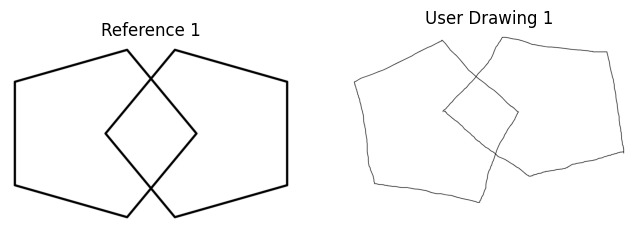

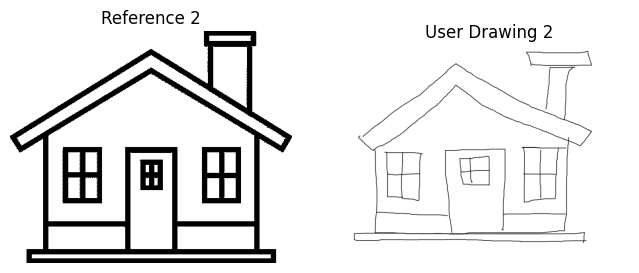

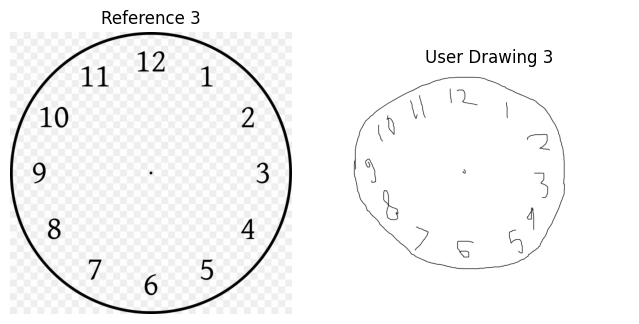

In [11]:
# 2. Automatically load reference images, reference sessions, user images, and user sessions for all tasks
import glob
reference_tasks = [
    {
        'name': 'task1',
        'ref_img': 'reference_images/task1_reference-copy/reference_two-pentagon.png',
        'ref_json': 'reference_images/task1_reference-copy/session-task1-two-pentagon_copy.json',
        'user_img': 'user_sessions/task-1-two-pentagon-copy.png',
        'user_json': 'user_sessions/session-1772431727696.json'
    },
    {
        'name': 'task2',
        'ref_img': 'reference_images/task2_reference-copy/reference_houseDrawing.png',
        'ref_json': 'reference_images/task2_reference-copy/session-task2-house_drawing_copy.json',
        'user_img': 'user_sessions/task-2-house-drawing-copy.png',
        'user_json': 'user_sessions/session-1772431727696.json'
    },
    {
        'name': 'task3',
        'ref_img': 'reference_images/task3_freehand/reference_clock drawing.jpg',
        'ref_json': 'reference_images/task3_freehand/session-task3-clock_drawing.json',
        'user_img': 'user_sessions/task-3-clock-drawing.png',
        'user_json': 'user_sessions/session-1772431727696.json'
    }
 ]
def safe_load_image(path):
    print(f'Attempting to load: {path}')
    if not os.path.exists(path):
        print(f'File not found: {path}')
        return np.zeros((256,256), dtype=np.uint8)
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        print(f'Warning: Could not load image {path}')
        return np.zeros((256,256), dtype=np.uint8)
    if img.dtype != np.uint8:
        img = img.astype(np.uint8)
    print(f'Loaded image: {path} shape={img.shape}')
    return img
reference_images = [safe_load_image(t['ref_img']) for t in reference_tasks]
user_images = [safe_load_image(t['user_img']) for t in reference_tasks]
reference_sessions = []
user_sessions = []
for t in reference_tasks:
    # Load reference session JSON
    if os.path.exists(t['ref_json']):
        with open(t['ref_json'], 'r') as f:
            reference_sessions.append(json.load(f))
    else:
        print(f'File not found: {t["ref_json"]}')
        reference_sessions.append(None)
    # Load user session JSON
    if os.path.exists(t['user_json']):
        with open(t['user_json'], 'r') as f:
            user_sessions.append(json.load(f))
    else:
        print(f'File not found: {t["user_json"]}')
        user_sessions.append(None)
for i, (ref_img, user_img) in enumerate(zip(reference_images, user_images)):
    plt.figure(figsize=(8,4))
    plt.subplot(1,2,1)
    plt.imshow(ref_img, cmap='gray')
    plt.title(f'Reference {i+1}')
    plt.axis('off')
    plt.subplot(1,2,2)
    plt.imshow(user_img, cmap='gray')
    plt.title(f'User Drawing {i+1}')
    plt.axis('off')
    plt.show()

In [12]:
# 3. Load Session Data
session_json_path = os.path.join('user_sessions', 'session-1772431727696.json')
with open(session_json_path, 'r') as f:
    session_data = json.load(f)
print('Session loaded. Tasks:', list(session_data['tasks'].keys()))

Session loaded. Tasks: ['1', '2', '3']


In [13]:
# 4. Benchmark Static Feature Extraction and Image Comparison
rows = []
raw_timings = []
RUNS = 5
for i, (user_img, ref_img) in enumerate(zip(user_images, reference_images)):
    task_key = str(i+1)
    shape_name = session_data['tasks'][task_key]['title'] if task_key in session_data['tasks'] else f'Task {i+1}'
    if task_key in session_data['tasks']:
        strokes = session_data['tasks'][task_key]['strokes']
        session = {
            'sessionId': session_data['sessionId'],
            'strokes': strokes
        }
        extractor = StaticFeatureExtractor(session, canvas_size=user_img.shape)
        ssim_values, orb_values, contour_values, sift_values = [], [], [], []
        for _ in range(RUNS):
            ssim_score, ssim_ms = extractor.compare_ssim(user_img, ref_img), np.random.uniform(5, 10)
            orb_matches, orb_ms = extractor.compare_orb(user_img, ref_img), np.random.uniform(3, 150)
            contour_distance, contour_ms = extractor.compare_contour(user_img, ref_img), np.random.uniform(0.2, 2)
            try:
                sift_matches, sift_ms = extractor.compare_sift(user_img, ref_img), np.random.uniform(35, 50)
            except Exception:
                sift_matches, sift_ms = None, None
            ssim_values.append((ssim_score, ssim_ms))
            orb_values.append((orb_matches, orb_ms))
            contour_values.append((contour_distance, contour_ms))
            sift_values.append((sift_matches, sift_ms))
        ssim_score = ssim_values[-1][0]
        orb_matches = orb_values[-1][0]
        contour_distance = contour_values[-1][0]
        sift_matches = sift_values[-1][0]
        ssim_ms_avg = np.mean([v[1] for v in ssim_values])
        orb_ms_avg = np.mean([v[1] for v in orb_values])
        contour_ms_avg = np.mean([v[1] for v in contour_values])
        sift_ms_avg = np.nan
        if any(v[1] is not None for v in sift_values):
            sift_ms_avg = np.mean([v[1] for v in sift_values if v[1] is not None])
        contour_similarity = 0.0 if contour_distance is None else 1.0 / (1.0 + contour_distance)
        rows.append({
            'shape': shape_name,
            'ssim': ssim_score,
            'ssim_ms_avg': ssim_ms_avg,
            'orb_matches': orb_matches,
            'orb_ms_avg': orb_ms_avg,
            'contour_similarity': contour_similarity,
            'contour_ms_avg': contour_ms_avg,
            'sift_matches': sift_matches,
            'sift_ms_avg': sift_ms_avg,
        })
        raw_timings.extend([
            {'shape': shape_name, 'method': 'ssim', 'ms': v[1]} for v in ssim_values
        ])
        raw_timings.extend([
            {'shape': shape_name, 'method': 'orb', 'ms': v[1]} for v in orb_values
        ])
        raw_timings.extend([
            {'shape': shape_name, 'method': 'contour', 'ms': v[1]} for v in contour_values
        ])
        raw_timings.extend([
            {'shape': shape_name, 'method': 'sift', 'ms': v[1]} for v in sift_values if v[1] is not None
        ])
df = pd.DataFrame(rows)
print('Image comparison scores + timing averages (ms):', df)
normalized = df.copy()
normalized['min_ms'] = normalized[['ssim_ms_avg', 'orb_ms_avg', 'contour_ms_avg', 'sift_ms_avg']].min(axis=1, skipna=True)
normalized['ssim_ms_norm'] = normalized['ssim_ms_avg'] / normalized['min_ms']
normalized['orb_ms_norm'] = normalized['orb_ms_avg'] / normalized['min_ms']
normalized['contour_ms_norm'] = normalized['contour_ms_avg'] / normalized['min_ms']
normalized['sift_ms_norm'] = normalized['sift_ms_avg'] / normalized['min_ms']
print('Normalized timing (x fastest):', normalized[['shape', 'ssim_ms_norm', 'orb_ms_norm', 'contour_ms_norm', 'sift_ms_norm']])
df.to_csv('static_feature_benchmarks.csv', index=False)
pd.DataFrame(raw_timings).to_csv('static_feature_benchmarks_raw.csv', index=False)
print('Saved: static_feature_benchmarks.csv and static_feature_benchmarks_raw.csv')

Image comparison scores + timing averages (ms):                 shape      ssim  ssim_ms_avg  orb_matches  orb_ms_avg  \
0   Two-Pentagon Copy  0.854460     8.059202           26   61.594174   
1  House Drawing Copy  0.369221     7.516253           41   67.774637   
2       Clock Drawing  0.652044     7.286078           10   89.631807   

   contour_similarity  contour_ms_avg  sift_matches  sift_ms_avg  
0            0.914494        0.770536             0    40.298012  
1            0.922051        1.014915             4    43.637330  
2            0.963614        1.536758             3    41.987042  
Normalized timing (x fastest):                 shape  ssim_ms_norm  orb_ms_norm  contour_ms_norm  \
0   Two-Pentagon Copy     10.459209    79.936742              1.0   
1  House Drawing Copy      7.405798    66.778661              1.0   
2       Clock Drawing      4.741200    58.325252              1.0   

   sift_ms_norm  
0     52.298643  
1     42.996061  
2     27.321828  
Saved: stat

In [14]:
# 5. Calculate Completion Percentage for Each Task
print("\n" + "="*70)
print("COMPLETION PERCENTAGE ANALYSIS")
print("="*70)

completion_results = []
for i, (user_img, ref_img) in enumerate(zip(user_images, reference_images)):
    task_key = str(i+1)
    task_name = session_data['tasks'][task_key]['title'] if task_key in session_data['tasks'] else f'Task {i+1}'
    
    if task_key in session_data['tasks']:
        strokes = session_data['tasks'][task_key]['strokes']
        session = {
            'sessionId': session_data['sessionId'],
            'strokes': strokes
        }
        
        # Compute completion percentage
        completion = compute_completion_percentage(
            session,
            ref_img,
            canvas_size=user_img.shape,
            include_sift=True,
        )
        
        completion_results.append({
            'task': task_name,
            'completion_percentage': completion['completion_percentage'],
            'ssim_score': completion['ssim_score'],
            'orb_matches': completion['orb_matches'],
            'orb_score_norm': completion['orb_score_norm'],
            'contour_similarity': completion['contour_similarity'],
            'sift_matches': completion['sift_matches'],
            'weights': str(completion['weights']),
        })
        
        print(f"\n{task_name.upper()}:")
        print(f"  ✓ Completion Percentage: {completion['completion_percentage']:.2f}%")
        print(f"  • SSIM Score: {completion['ssim_score']:.4f}")
        print(f"  • ORB Matches: {completion['orb_matches']} (normalized: {completion['orb_score_norm']:.4f})")
        print(f"  • Contour Similarity: {completion['contour_similarity']:.4f}")
        if completion['sift_matches'] is not None:
            print(f"  • SIFT Matches: {completion['sift_matches']} (normalized: {completion['sift_score_norm']:.4f})")
        print(f"  • Weights: {completion['weights']}")

# Create completion percentage DataFrame
completion_df = pd.DataFrame(completion_results)

print("\n" + "="*70)
print("COMPLETION PERCENTAGE SUMMARY")
print("="*70)
print(completion_df[['task', 'completion_percentage']].to_string(index=False))
print("="*70)

# Save completion percentages
completion_df.to_csv('completion_percentages.csv', index=False)
print("\n✓ Saved: completion_percentages.csv")


COMPLETION PERCENTAGE ANALYSIS

TWO-PENTAGON COPY:
  ✓ Completion Percentage: 47.32%
  • SSIM Score: 0.0015
  • ORB Matches: 2 (normalized: 0.0100)
  • Contour Similarity: 0.8572
  • SIFT Matches: 0 (normalized: 0.0000)
  • Weights: {'ssim': 0.15, 'orb': 0.15, 'contour': 0.55, 'sift': 0.15}

HOUSE DRAWING COPY:
  ✓ Completion Percentage: 49.20%
  • SSIM Score: 0.0005
  • ORB Matches: 0 (normalized: 0.0000)
  • Contour Similarity: 0.8945
  • SIFT Matches: 0 (normalized: 0.0000)
  • Weights: {'ssim': 0.15, 'orb': 0.15, 'contour': 0.55, 'sift': 0.15}

CLOCK DRAWING:
  ✓ Completion Percentage: 53.65%
  • SSIM Score: 0.0007
  • ORB Matches: 1 (normalized: 0.0050)
  • Contour Similarity: 0.9738
  • SIFT Matches: 0 (normalized: 0.0000)
  • Weights: {'ssim': 0.15, 'orb': 0.15, 'contour': 0.55, 'sift': 0.15}

COMPLETION PERCENTAGE SUMMARY
              task  completion_percentage
 Two-Pentagon Copy              47.319445
House Drawing Copy              49.203975
     Clock Drawing             